# 05. Đánh Giá & So Sánh Hiệu Năng Mô Hình Theo Mốc Tuần Cảnh Báo Sớm
**Đồ án môn học:** Hệ thống Hỗ trợ Ra quyết định (*Decision Support Systems* - `IS254.R11`)  
**Thiết lập thực nghiệm:** `5-Fold StratifiedGroupKFold` chia theo `id_student` trên `25.814` lượt đăng ký (`23.345` sinh viên duy nhất)  
**Các mốc tuần đánh giá:** `T ∈ {2, 4, 8, 12, 16, 20}` (bao gồm đầy đủ `T = 2, 8, 16` của Bảng 4 trong Đề cương)

---


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams['figure.dpi'] = 115
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

folds_df = pd.read_csv(os.path.join('..', 'data', 'processed', 'benchmark_folds.csv'))
sum_df = pd.read_csv(os.path.join('..', 'data', 'processed', 'benchmark_summary.csv'))
with open(os.path.join('..', 'models', 'sample_dbn_explanation.json'), encoding='utf-8') as f:
    sample_exp = json.load(f)

print(f"Tổng số lượt chạy mô hình (5 folds x 6 tuần x 4 mô hình): {len(folds_df)} bản ghi")
b4 = sum_df[sum_df['week'].isin([2, 8, 16])][[
    'week', 'model', 'accuracy_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'auc_roc_mean', 'auc_pr_mean'
]].round(4)
display(b4)


Tổng số lượt chạy mô hình (5 folds x 6 tuần x 4 mô hình): 120 bản ghi


,week,model,accuracy_mean,precision_mean,recall_mean,f1_mean,auc_roc_mean,auc_pr_mean
0,2,DBN,0.5776,0.4838,0.6754,0.5636,0.6282,0.5210
1,2,LSTM,0.6211,0.5304,0.5616,0.5439,0.6601,0.5629
2,2,Baseline_RF,0.6214,0.5276,0.6020,0.5623,0.6667,0.5718
3,2,Baseline_LR,0.6235,0.5296,0.6117,0.5677,0.6678,0.5677
8,8,DBN,0.7282,0.6825,0.6126,0.6456,0.7617,0.7087
9,8,LSTM,0.7469,0.7083,0.6400,0.6710,0.8044,0.7649
10,8,Baseline_RF,0.7452,0.6967,0.6543,0.6748,0.8066,0.7675
11,8,Baseline_LR,0.7408,0.6829,0.6698,0.6762,0.7996,0.7504
16,16,DBN,0.8034,0.7696,0.7336,0.7510,0.8605,0.8398
17,16,LSTM,0.8136,0.7970,0.7254,0.7586,0.8822,0.8694


## 1. Đường cong Hiệu năng Dự đoán sớm theo Tuần `T ∈ {2, 4, 8, 12, 16, 20}` (Kiểm chứng RQ2, H1 & H2)

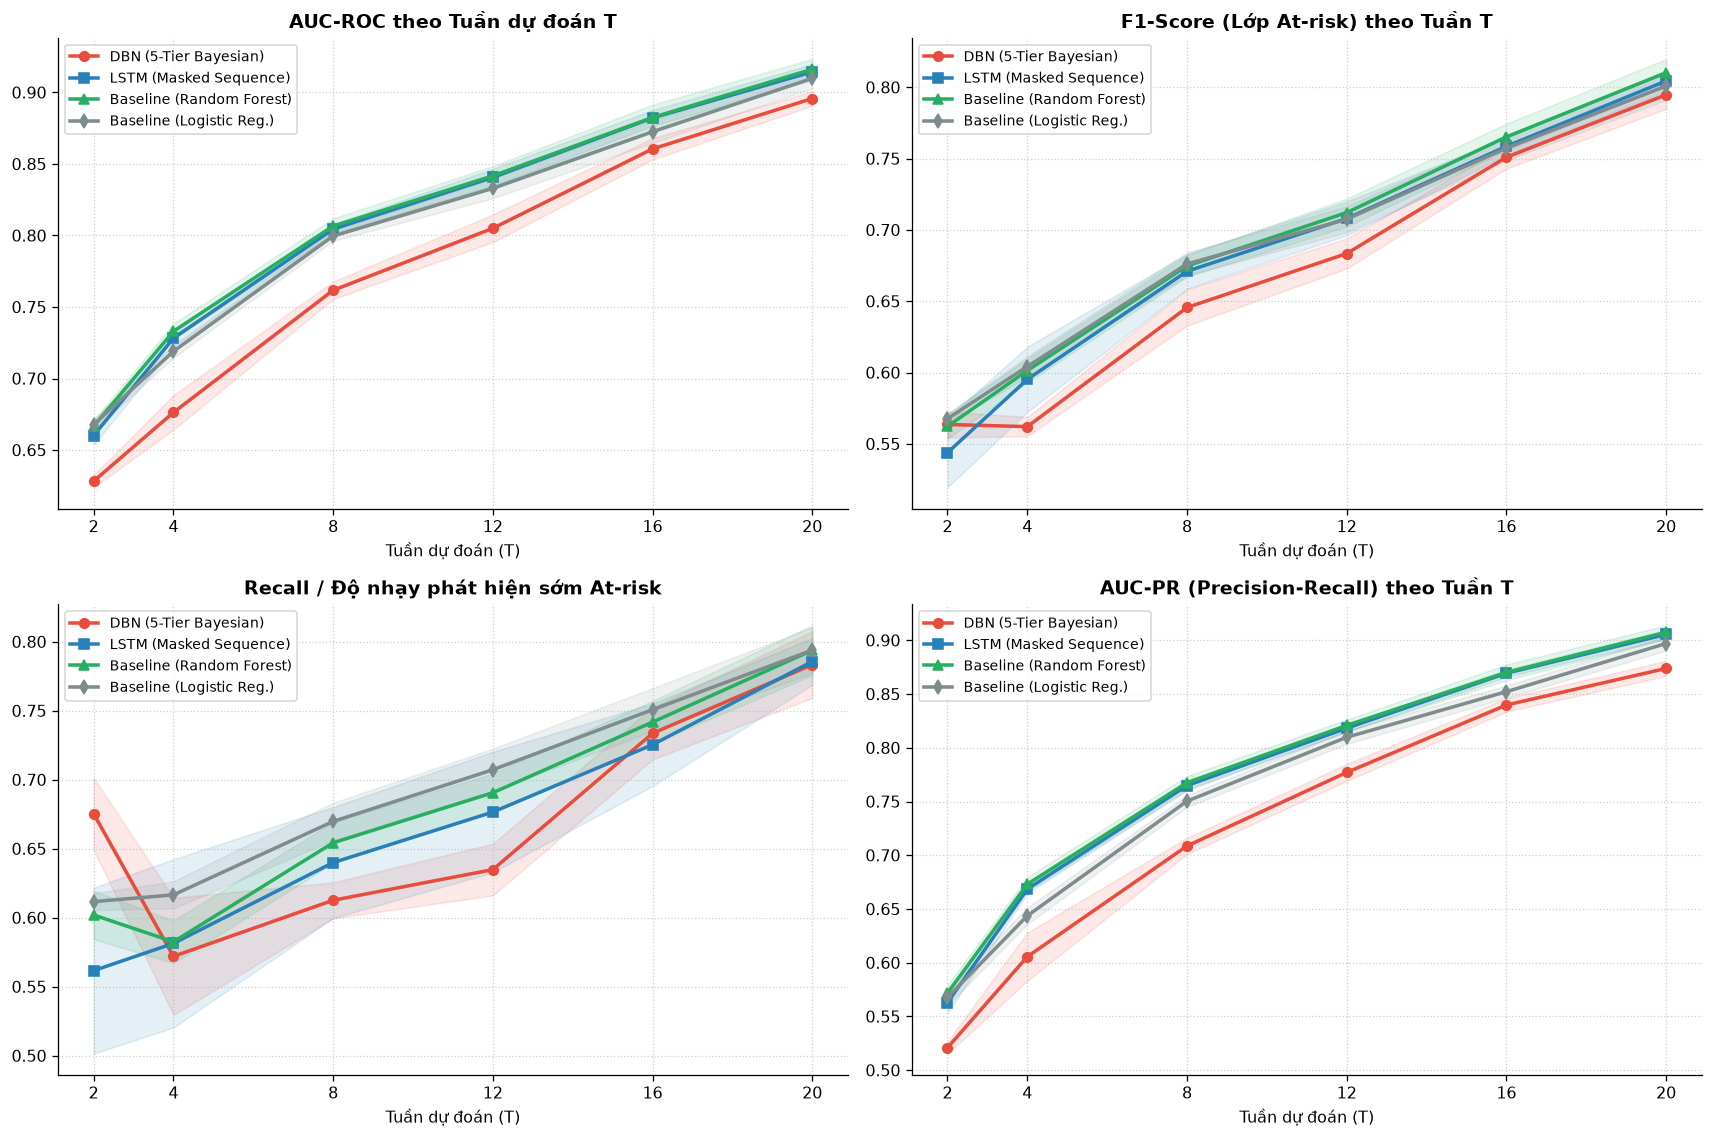

In [2]:
palette = {
    'DBN': '#e74c3c',
    'LSTM': '#2980b9',
    'Baseline_RF': '#27ae60',
    'Baseline_LR': '#7f8c8d'
}
labels_map = {
    'DBN': 'DBN (5-Tier Bayesian)',
    'LSTM': 'LSTM (Masked Sequence)',
    'Baseline_RF': 'Baseline (Random Forest)',
    'Baseline_LR': 'Baseline (Logistic Reg.)'
}
markers = {'DBN': 'o', 'LSTM': 's', 'Baseline_RF': '^', 'Baseline_LR': 'd'}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
metrics_cfg = [
    ('auc_roc', 'AUC-ROC theo Tuần dự đoán T', axes[0, 0]),
    ('f1', 'F1-Score (Lớp At-risk) theo Tuần T', axes[0, 1]),
    ('recall', 'Recall / Độ nhạy phát hiện sớm At-risk', axes[1, 0]),
    ('auc_pr', 'AUC-PR (Precision-Recall) theo Tuần T', axes[1, 1]),
]

for met, title, ax in metrics_cfg:
    for m_key in ['DBN', 'LSTM', 'Baseline_RF', 'Baseline_LR']:
        sub = sum_df[sum_df['model'] == m_key].sort_values('week')
        x = sub['week'].to_numpy()
        y = sub[f'{met}_mean'].to_numpy()
        s = sub[f'{met}_std'].to_numpy()
        ax.plot(x, y, marker=markers[m_key], linewidth=2.2, color=palette[m_key], label=labels_map[m_key])
        ax.fill_between(x, y - s, y + s, color=palette[m_key], alpha=0.12)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Tuần dự đoán (T)')
    ax.set_xticks([2, 4, 8, 12, 16, 20])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(frameon=True, fontsize=8.8)

plt.tight_layout()
plt.show()


## 2. Phân tích Độ ổn định qua 5 Fold tại `T = 2` (H1) và Bước nhảy giữa kỳ `T = 8, 16` (H2)

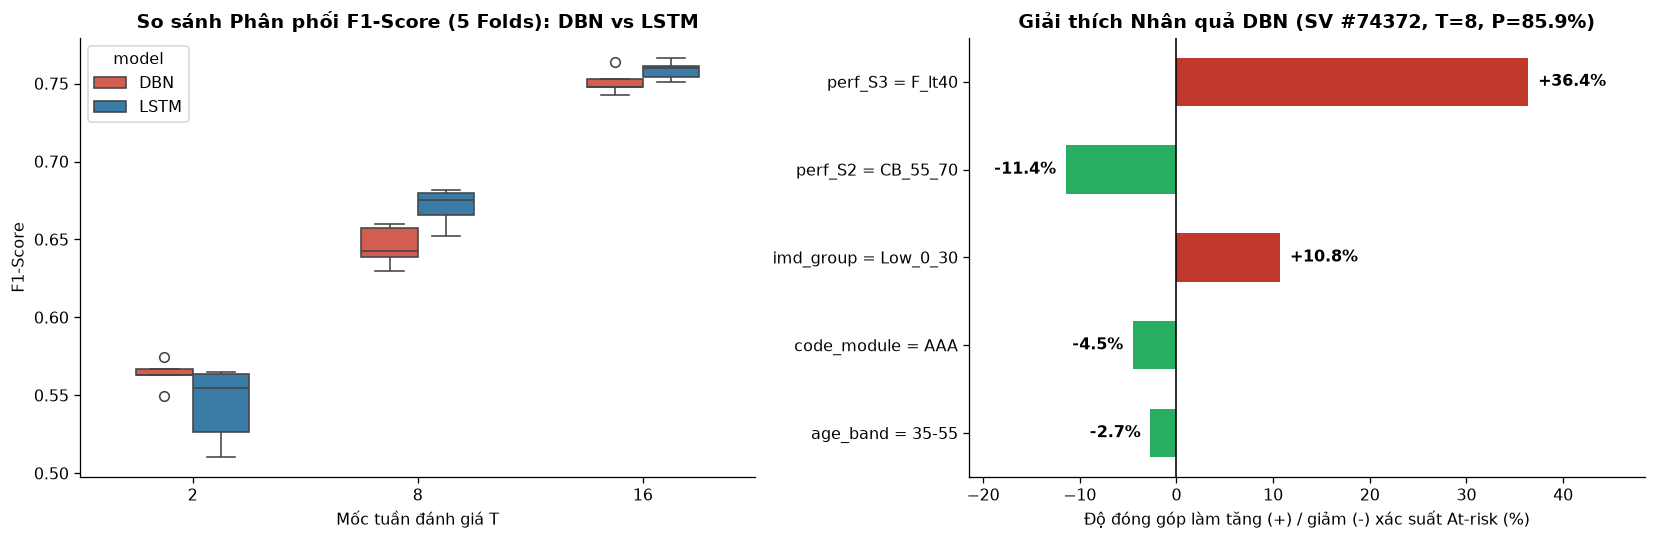

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

# Boxplot F1-Score tại T=2, 8, 16 giữa DBN và LSTM
sub_dl = folds_df[folds_df['week'].isin([2, 8, 16]) & folds_df['model'].isin(['DBN', 'LSTM'])]
sns.boxplot(
    data=sub_dl, x='week', y='f1', hue='model',
    palette={'DBN': '#e74c3c', 'LSTM': '#2980b9'}, width=0.5, ax=axes[0]
)
axes[0].set_title('So sánh Phân phối F1-Score (5 Folds): DBN vs LSTM', fontweight='bold')
axes[0].set_xlabel('Mốc tuần đánh giá T')
axes[0].set_ylabel('F1-Score')

# Biểu đồ Giải thích nhân quả DBN (Hypothesis H3) cho sinh viên mẫu ở T=8
factors = [f"{it['factor']} = {it['value']}" for it in sample_exp['top_factors']][::-1]
deltas = [it['delta_prob'] * 100 for it in sample_exp['top_factors']][::-1]
colors = ['#c0392b' if d > 0 else '#27ae60' for d in deltas]

bars = axes[1].barh(factors, deltas, color=colors, height=0.55)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title(
    f"Giải thích Nhân quả DBN (SV #{sample_exp['id_student']}, T={sample_exp['week_t']}, P={sample_exp['prob_at_risk']*100:.1f}%)",
    fontweight='bold'
)
axes[1].set_xlabel('Độ đóng góp làm tăng (+) / giảm (-) xác suất At-risk (%)')
axes[1].set_xlim(min(deltas) - 10, max(deltas) + 12)
for b, d in zip(bars, deltas):
    offset = 1.0 if d >= 0 else -1.0
    ha = 'left' if d >= 0 else 'right'
    axes[1].text(d + offset, b.get_y() + b.get_height()/2, f"{d:+.1f}%", va='center', ha=ha, fontweight='bold')

plt.tight_layout()
plt.show()
